# 02 — Baselines

**Setup:** day-ahead. Forecasts for day D are issued at 00:00 UTC on D, using only data up to D-1
(all baselines use lags ≥ 24 h). Scored on 2019 (normal year) and Jan–Sep 2020 (COVID stress test).
The TSOs' official day-ahead forecast is the bar to beat.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from energy_demand_forecasting.baselines import (
    naive_day,
    seasonal_naive_week,
    weekday_mean,
)
from energy_demand_forecasting.data import PROJECT_ROOT
from energy_demand_forecasting.evaluation import PERIODS, evaluate
from energy_demand_forecasting.features import (
    TARGET,
    TSO_FORECAST,
    calendar_features,
    load_dataset,
)

df = load_dataset()
y = df[TARGET]
preds = pd.concat(
    [
        naive_day(y),
        seasonal_naive_week(y),
        weekday_mean(y, 4),
        df[TSO_FORECAST].rename("tso_dayahead"),
    ],
    axis=1,
)
res = evaluate(y, preds)
res.to_csv(PROJECT_ROOT / "reports" / "baselines_metrics.csv")
res

MAE     RMSE  MAPE_%     n
period      model                                          
test_2019   naive_day        4557.69  6943.99    8.33  8760
            snaive_week      2558.15  4464.97    4.74  8760
            weekday_mean_4w  2754.17  4331.24    5.09  8760
            tso_dayahead     1989.25  2489.40    3.52  8760
stress_2020 naive_day        4049.46  6161.74    7.77  6576
            snaive_week      2226.51  3777.58    4.30  6576
            weekday_mean_4w  2507.64  3855.89    4.75  6576
            tso_dayahead     1458.90  1891.88    2.81  6576

## Where do the baselines fail? Error by day type (2019)

In [2]:
cal = calendar_features(df.index)
s, e = PERIODS["test_2019"]
day_type = pd.Series("workday", index=df.index)
day_type[cal.is_weekend == 1] = "weekend"
day_type[(cal.holiday_share > 0.5) | (cal.is_xmas_period == 1)] = "holiday/xmas"
# A workday right after a weekend/holiday, or right before one, breaks the "same as yesterday" logic
abs_err = preds.sub(y, axis=0).abs().loc[s:e] / 1000
by_type = abs_err.groupby(day_type.loc[s:e]).mean().round(2)
by_type["share_of_hours"] = day_type.loc[s:e].value_counts(normalize=True).round(3)
by_type

,naive_day,snaive_week,weekday_mean_4w,tso_dayahead,share_of_hours
holiday/xmas,5.61,9.70,12.54,1.80,0.047
weekend,6.25,1.66,1.63,1.36,0.279
workday,3.78,2.44,2.55,2.26,0.674


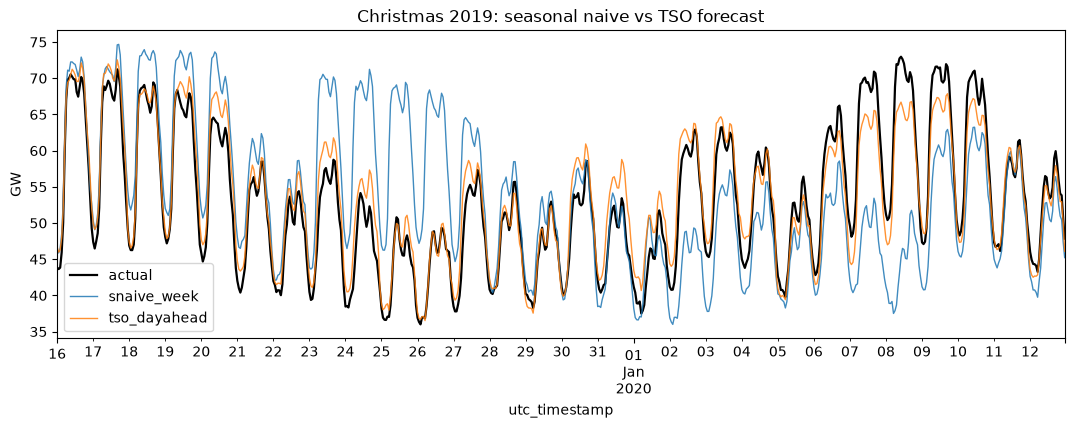

In [3]:
fig, ax = plt.subplots(figsize=(13, 4))
win = slice("2019-12-16", "2020-01-12")
(y.loc[win] / 1000).plot(ax=ax, color="k", lw=1.6, label="actual")
for c in ["snaive_week", "tso_dayahead"]:
    (preds[c].loc[win] / 1000).plot(ax=ax, lw=1, alpha=0.85, label=c)
ax.set(title="Christmas 2019: seasonal naive vs TSO forecast", ylabel="GW")
ax.legend()
fig.savefig(
    PROJECT_ROOT / "reports" / "figures" / "09_baselines_christmas.png",
    bbox_inches="tight",
)